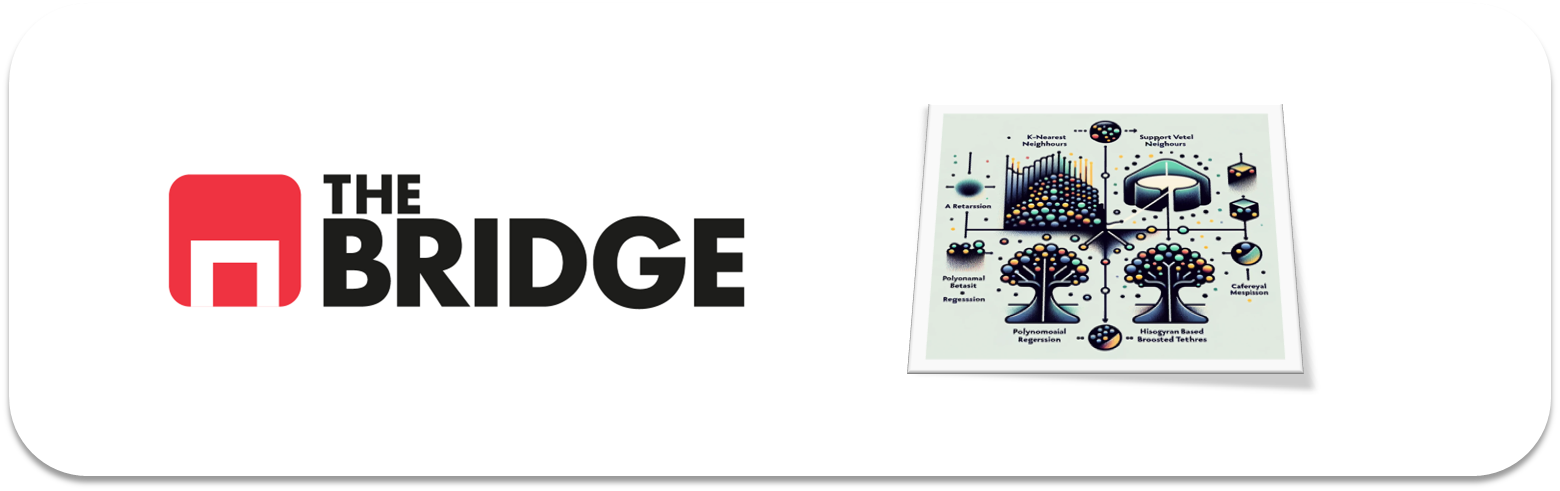

## Regresión Polinómica

### Concepto y modelado


En muchas ocasiones la relación entre los datos no va a ser lineal, por lo que una simple regresión lineal no se va a ajustar bien a nuestra problemática.

Por ejemplo, en el siguiente ejemplo encajaría muy bien una regresión lineal.

In [24]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

df = pd.read_csv('../data/salary_data.csv')
df.head()

,YearsExperience,Salary
0,1.1,39343
1,1.3,46205
2,1.5,37731
3,2.0,43525
4,2.2,39891


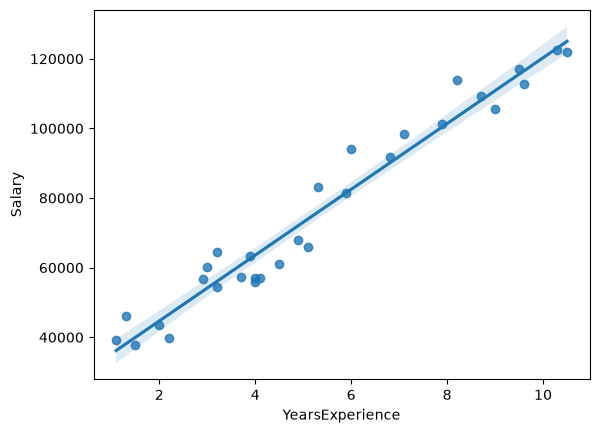

In [25]:
sns.regplot(data=df,  # regplot una nueva herramienta visual para tu caja de herramientas
            x="YearsExperience",
            y="Salary");

En la vida real los problemas son más complejos, ya que los salarios no llevan una subida lineal vs años de experiencia, dependerá también de la carrera profesional: profesor, ingeniero, doctor...

Otra posible representación del salario podría ser en función del puesto de trabajo.

In [26]:
df = pd.read_csv('../data/position_salaries.csv')
df

,Position,Level,Salary
0,Business Analyst,1,45000
1,Junior Consultant,2,50000
2,Senior Consultant,3,60000
3,Manager,4,80000
4,Country Manager,5,110000
5,Region Manager,6,150000
6,Partner,7,200000
7,Senior Partner,8,300000
8,C-level,9,500000
9,CEO,10,1000000


Vamos a construir un modelo que tenga en cuenta el "nivel" profesional

In [27]:
X = df.iloc[:, 1:2].values
y = df.iloc[:, 2].values

In [28]:
X

array([[ 1],
       [ 2],
       [ 3],
       [ 4],
       [ 5],
       [ 6],
       [ 7],
       [ 8],
       [ 9],
       [10]])

In [29]:
y

array([  45000,   50000,   60000,   80000,  110000,  150000,  200000,
        300000,  500000, 1000000])

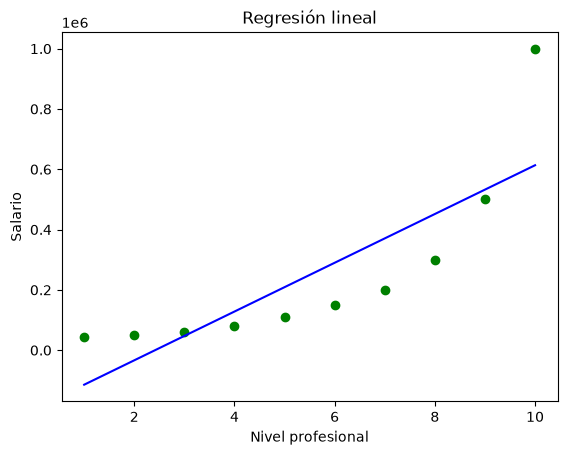

In [30]:
lin_reg = LinearRegression()
lin_reg.fit(X, y)

# Visualizamos el resultado de la regresión lineal
def viz_linear():
    plt.scatter(X, y, color='green')
    plt.plot(X, lin_reg.predict(X), color='blue')
    plt.title('Regresión lineal')
    plt.xlabel('Nivel profesional')
    plt.ylabel('Salario')
    plt.show()

viz_linear()

Vemos que en este caso, la regresión lineal no se ajusta nada bien a los datos, por lo que habrá que probar otras alternativas. Observa los errores (residuos): no se reparten al azar alrededor de 0, sino que siguen un patrón en forma de U, señal de que la relación no es lineal:

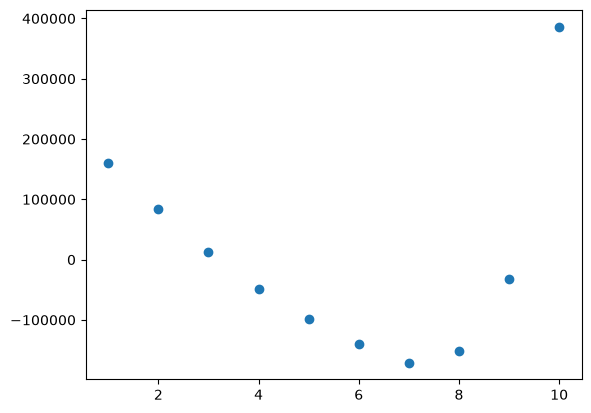

In [ ]:
plt.scatter(X, y - lin_reg.predict(X));

Y aquí es donde entra la **regresión polinómica**. Partimos de la regresión lineal $y = a_0 + a_1 x_1 + a_2 x_2 + a_3 x_3 + ...$ (donde $x_i$ son las features y $a_i$ los coeficientes, pesos o parámetros) y le aplicamos una transformación sencilla pero potente: además de las features, usamos también sus cuadrados, cubos, etc. y los productos entre ellas:

$$y = a_0 + a_1 x_1 + a_2 x_1^2 + a_3 (x_1 x_2) + a_4 x_2^2 + a_5 x_3^2 + a_6 (x_1 x_3) + a_7 (x_2 x_3) + a_8 x_1^3 + ...$$

El grado de la regresión polinómica es el máximo exponente al que elevaremos las features (en el caso anterior sería 3). Por otro lado, fíjate que es como crear una regresión lineal incluyendo las features "creadas" o "sintéticas" ($x_1^2, x_2^2, x_3^2, x_1^3, x_2^3, x_3^3, x_1*x_2,x_1*x_3,x_2*x_3,x_1*x_2^2,...$, etc)

Por supuesto, `sklearn` tiene una clase que se encarga de obtener esas features "sintéticas" y luego nosotros haremos la regresión lineal con todo el nuevo conjunto de datos. Eso sí, tendrás que indicarle el grado a través del argumento `degree`. La clase es `PolynomialFeatures` (si hay varias features, también crea los productos combinados entre ellas). Veamos cómo:

In [12]:
X

array([[ 1],
       [ 2],
       [ 3],
       [ 4],
       [ 5],
       [ 6],
       [ 7],
       [ 8],
       [ 9],
       [10]])

In [31]:
poly_feat = PolynomialFeatures(degree=3)
poly_feat.fit(X)
X_poly = poly_feat.transform(X)
X_poly

array([[   1.,    1.,    1.,    1.],
       [   1.,    2.,    4.,    8.],
       [   1.,    3.,    9.,   27.],
       [   1.,    4.,   16.,   64.],
       [   1.,    5.,   25.,  125.],
       [   1.,    6.,   36.,  216.],
       [   1.,    7.,   49.,  343.],
       [   1.,    8.,   64.,  512.],
       [   1.,    9.,   81.,  729.],
       [   1.,   10.,  100., 1000.]])

Como solo teníamos una feature ($x_1$) creará un nuevo dataset con:

$$(x_1^0, x_1^1, x_1^2, x_1^3)$$

Ahora ejecutamos el modelado y veamos la comparativa:

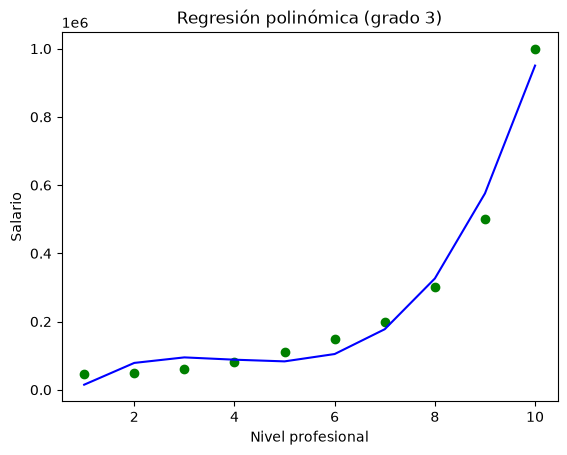

In [14]:
# Regresión lineal sobre las features polinómicas
pol_reg = LinearRegression()
pol_reg.fit(X_poly, y)

# Visualizamos el resultado de la regresión polinómica
def viz_polynomial():
    plt.scatter(X, y, color='green')
    plt.plot(X, pol_reg.predict(poly_feat.transform(X)), color='blue')
    plt.title('Regresión polinómica (grado 3)')
    plt.xlabel('Nivel profesional')
    plt.ylabel('Salario')
    plt.show()

viz_polynomial()

### Un momento, ¿el regresor lineal no ajustaba rectas?

La clave está en que la regresión es “lineal” en los coeficientes, no en la variable de entrada.  

Con `polynomial features`, el modelo no ajusta una recta en el espacio original, sino que **ajusta un hiperplano en un espacio ampliado**, y ese hiperplano, visto desde el espacio original, **se ve como una curva**.

En nuestro ejemplo, en el nuevo espacio de 4 dimensiones que hemos creado (x^0, x^1, x^2, x^3) el modelo ajusta un hiperplano, pero los datos transformados viven sobre una curva dentro de ese espacio, y al proyectar el hiperplano de vuelta sobre el eje x obtienes una curva.

### Predicciones

Como para poder ajustar el modelo hemos aplicado una transformación a los datos de entrenamiento (X), **para obtener las predicciones de un nuevo valor** (o de un conjunto de test) **tendremos que aplicar también dicha transformación antes de darle los datos al modelo**.

In [ ]:
# Predicción de un nuevo valor con la regresión lineal
print(lin_reg.predict([[5.5]]))

# Predicción de un nuevo valor con la regresión polinómica: primero transformamos. 
# Si no el modelo no lo entiende
print(pol_reg.predict(poly_feat.transform([[5.5]])))

[249500.]
[89187.5]


In [34]:
pol_reg.coef_.shape

(4,)

### Sobreajuste

El problema es que si añadimos mucha complejidad (empleamos grados muy altos) podemos sobreajustar el modelo fácilmente. Para verlo vamos a crear unos datos sintéticos: 15 puntos que siguen una función seno con algo de ruido. Como queremos medir si el modelo generaliza, los separamos en train y test:

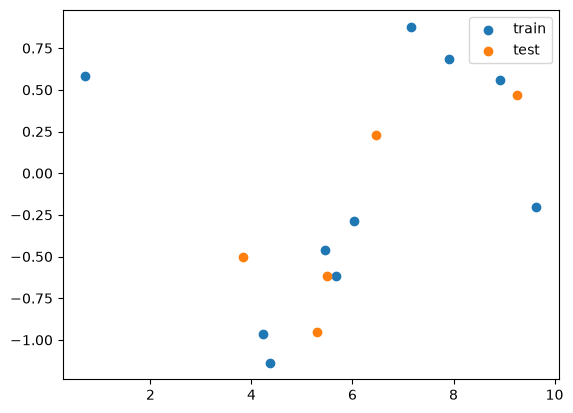

In [ ]:
from sklearn.model_selection import train_test_split

# Generamos datos sintéticos
np.random.seed(0)
X = np.random.rand(15, 1) * 10  # 15 puntos aleatorios entre 0 y 10. Multiplicado por 10 para q sea mas interpretable
y = np.sin(X).ravel() + np.random.normal(0, 0.2, X.shape[0])  # y = sin(x) con ruido

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

plt.scatter(X_train, y_train, label="train")
plt.scatter(X_test, y_test, label="test")
plt.legend();

Entrenemos regresiones polinómicas de distintos grados y comparemos el error (RMSE) en train y en test.

Un detalle importante: con grados altos las features toman valores muy dispares ($x$ va de 0 a 10, pero $x^{15}$ llega a $10^{15}$), y con escalas tan distintas el cálculo de la regresión se vuelve numéricamente inestable. Por eso, tras crear las features polinómicas, las **escalamos** con `StandardScaler` (ajustando solo con train, como siempre):

In [18]:
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import root_mean_squared_error

resultados = []
for grado in [1, 3, 5, 9, 15]:
    poly = PolynomialFeatures(degree=grado, include_bias=False)
    X_train_poly = poly.fit_transform(X_train)  # fit solo con train
    X_test_poly = poly.transform(X_test)

    scaler = StandardScaler()
    X_train_poly = scaler.fit_transform(X_train_poly)  # fit solo con train
    X_test_poly = scaler.transform(X_test_poly)

    modelo = LinearRegression()
    modelo.fit(X_train_poly, y_train)

    resultados.append({"grado": grado,
                       "n_features": X_train_poly.shape[1],
                       "RMSE_train": root_mean_squared_error(y_train, modelo.predict(X_train_poly)),
                       "RMSE_test": root_mean_squared_error(y_test, modelo.predict(X_test_poly))})

pd.DataFrame(resultados)

,grado,n_features,RMSE_train,RMSE_test
0,1,1,0.668102,0.482220
1,3,3,0.179093,0.441114
2,5,5,0.130693,0.236241
3,9,9,0.102230,0.584148
4,15,15,0.060217,1.223138


Fíjate en la evolución:
- Con grado 1 (una recta) el modelo es demasiado simple: error alto tanto en train como en test (**subajuste**).
- Al subir el grado hasta 5 ambos errores bajan: el modelo capta la forma del seno (grado 5 es el de menor error de test).
- A partir de ahí el error de train sigue bajando (casi a cero con grado 15), pero el de test se dispara: el modelo se ha aprendido el ruido de los 10 puntos de train (**sobreajuste**).

Veámoslo gráficamente con el modelo de grado 15:

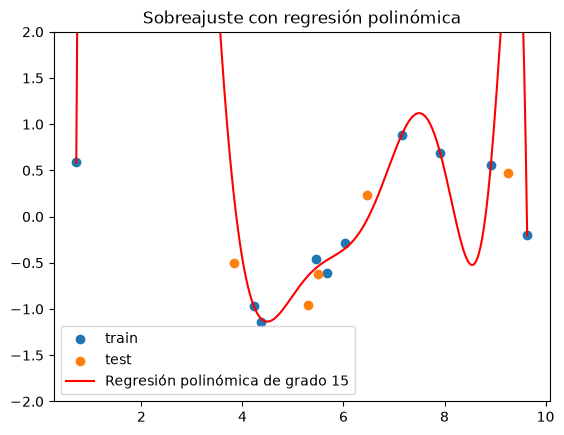

In [19]:
grado = 15
poly_overfitting = PolynomialFeatures(degree=grado, include_bias=False)
scaler_overfitting = StandardScaler()
X_train_poly = scaler_overfitting.fit_transform(poly_overfitting.fit_transform(X_train))
modelo = LinearRegression()
modelo.fit(X_train_poly, y_train)

X_curva = np.linspace(X.min(), X.max(), 300).reshape(-1, 1)
y_curva = modelo.predict(scaler_overfitting.transform(poly_overfitting.transform(X_curva)))

plt.scatter(X_train, y_train, label="train")
plt.scatter(X_test, y_test, label="test")
plt.plot(X_curva, y_curva, color='red', label=f"Regresión polinómica de grado {grado}")
plt.ylim(-2, 2)
plt.legend()
plt.title("Sobreajuste con regresión polinómica")
plt.show()

In [20]:
X_train_poly.shape

(10, 15)

La curva pasa prácticamente por todos los puntos de train, pero oscila para conseguirlo y se aleja de los de test: con 15 features y solo 10 filas, el modelo tiene libertad de sobra para memorizar el ruido.

¿Cómo lo evitamos? Una opción es bajar el grado (elegirlo comparando train y test, como acabamos de hacer). Otra, que veremos en el siguiente notebook, es mantener un modelo complejo pero "penalizarlo" para que no pueda usar coeficientes desmesurados: la **regularización**.